In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [13]:
df = pd.read_csv(r"C:\Users\jmanu\pythondecalfa\course_assignments\homework9\noisy_curvefit_data.csv")
print(df)

df.shape
# 100 rows, 6 columns

df.head()

           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0  -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1  -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2  -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3  -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4  -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
..       ...        ...        ...        ...        ...        ...
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850

[100 rows x 6 columns]


,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113


In [14]:
df.tail()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548
99,6.000000,-0.193438,-2.244792,1.930035,4.992414,-6.872850


In [17]:
print(df.columns)
# x, y_noise_1, y_noise_2, y_noise_3, y_noise_4, y_noise_5

Index(['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5'], dtype='str')


C:\Users\jmanu\AppData\Local\Temp\ipykernel_18512\973433880.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


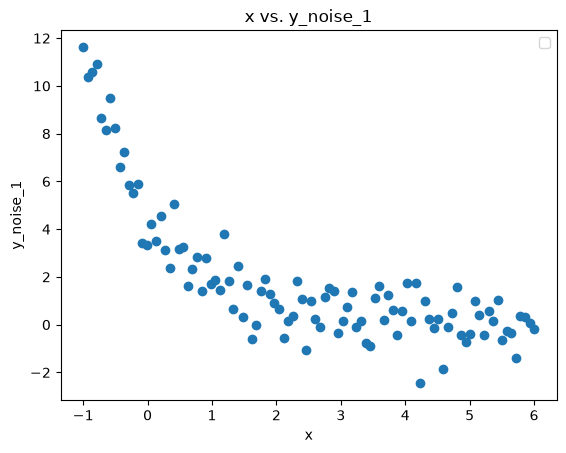

In [20]:
plt.scatter(df['x'], df['y_noise_1'])
plt.xlabel("x")
plt.ylabel("y_noise_1")
plt.title("x vs. y_noise_1")
plt.legend()

plt.show()

Fit: y = 4.71 * e^(-0.92 * x)


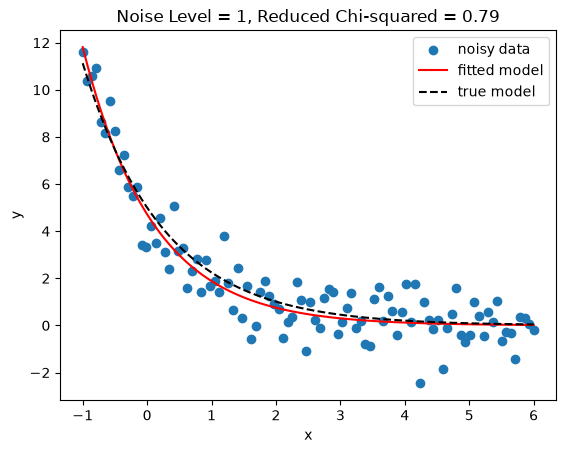

In [20]:
def model(x, A, k):
    return A * np.exp(-k * x)

p0 = [1,1]
popt, pcovt = curve_fit(model, df['x'], df['y_noise_1'], p0 = p0)
A_fit, k_fit = popt
print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = df['y_noise_1'] - model(df['x'], A_fit, k_fit)
chi2 = np.sum(residuals ** 2)
dof = len(df['x']) - len(popt)
chi2_reduced = chi2 / dof

plt.scatter(df['x'], df['y_noise_1'], label = "noisy data")

plt.plot(df['x'], model(df['x'], A_fit, k_fit), color = "red", label = "fitted model")

plt.plot(df['x'], model(df['x'], 5, 0.8), color = "black", linestyle = "--", label = "true model")

plt.title(f"Noise Level = 1, Reduced Chi-squared = {chi2_reduced:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

# this is all in one cell because it started crashing out when i ran it in separate cells :(

In [ ]:
# 2.3

In [22]:
def fit_model(x, y):
    p0 = [1, 1]

    popt, pcov = curve_fit(model, x, y, p0 = p0)
    A_fit, k_fit = popt

    residuals = y - model(x, A_fit, k_fit)

    chi2 = np.sum(residuals ** 2)
    dof = len(x) - len(popt)

    chi2_reduced = chi2 / dof

    return popt, chi2_reduced

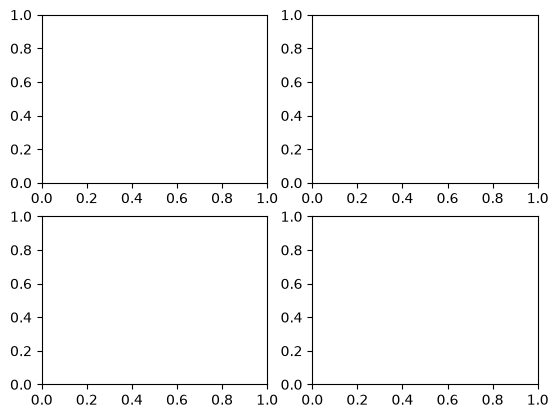

In [23]:
plt.subplots(2, 2)
plt.show()